In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

In [ ]:
hora_inicio = [
    "2:29:00",
    "2:35:00",
    "2:41:00",
    "2:47:00",
    "2:53:00",
    "2:59:00",
    "3:05:00",
    "3:11:00",
    "3:17:00",
    "3:22:30",
    "3:28:00",
    "3:33:30"
]

hora_fin = [
    "2:34:00",
    "2:40:00",
    "2:46:00",
    "2:52:00",
    "2:58:00",
    "3:04:00",
    "3:10:00",
    "3:16:00",
    "3:22:00",
    "3:27:30",
    "3:33:00",
    "3:38:30"
]

entradas_hombres = [
    19, 17, 9, 17, 14, 23,
    31, 17, 16, 17, 26, 16
]

entradas_mujeres = [
    13, 13, 11, 13, 20, 18,
    19, 19, 13, 11, 8, 15
]

entradas_inter = [
    0, 0, 0, 0, 0, 0,
    1, 0, 0, 0, 0, 0
]

salidas_hombres = [
    10, 9, 6, 6, 8, 20,
    16, 15, 15, 15, 25, 24
]

salidas_mujeres = [
    8, 8, 6, 9, 12, 13,
    7, 16, 16, 7, 12, 9
]

salidas_inter = [
    0, 0, 0, 0, 0, 0,
    1, 0, 0, 0, 0, 2
]

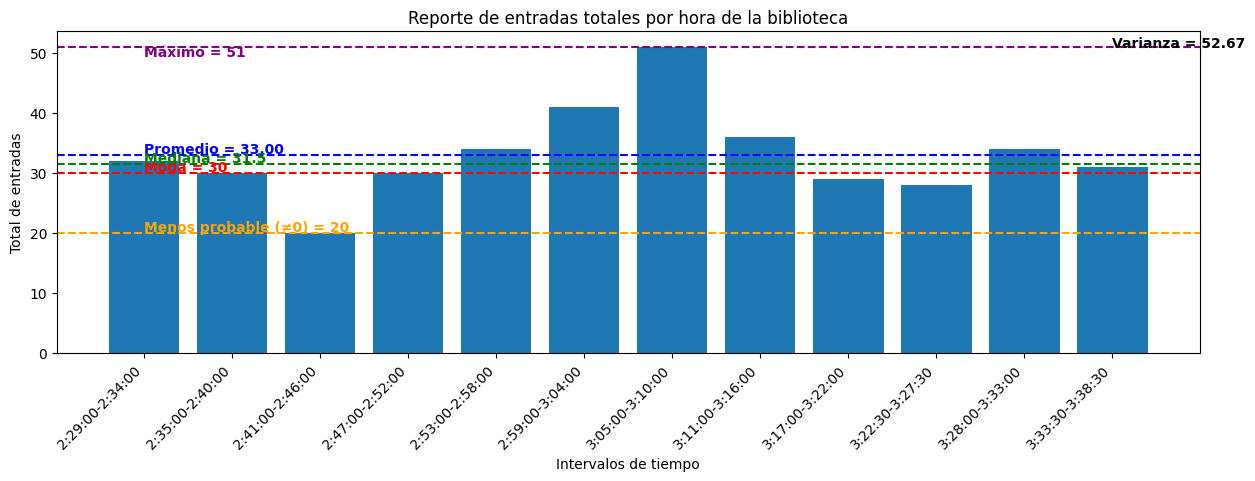

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
entrada_total = []
salida_total = []
for i in range(len(entradas_hombres)):
  entrada_total.append(entradas_hombres[i]+entradas_mujeres[i]+entradas_inter[i])
  salida_total.append(salidas_hombres[i]+salidas_mujeres[i]+salidas_inter[i])
plt.figure(figsize=(12, 4.5))
plt.bar(intervalos,entrada_total,label="moda:")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entrada_total)

# ===== VARIANZA =====
valor_varianza = np.var(entrada_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entrada_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

res_moda = stats.mode(entrada_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entrada_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entrada_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entrada_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')


plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de entradas')
plt.title('Reporte de entradas totales por hora de la biblioteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

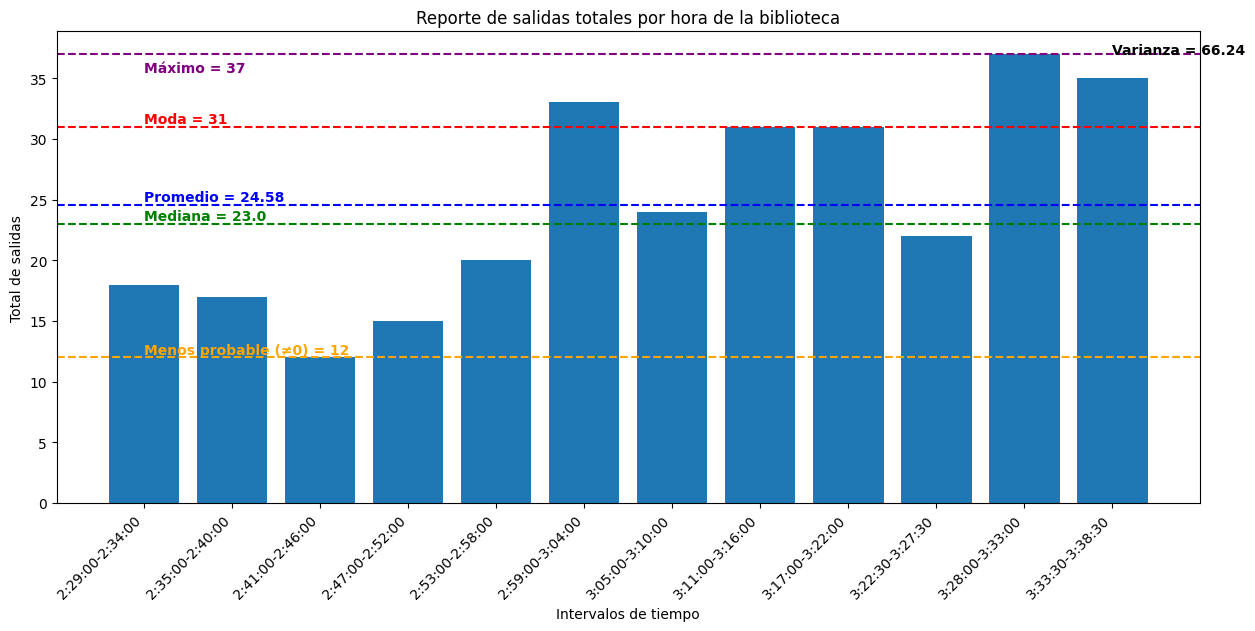

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,salida_total,label ="")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()


# ===== PROMEDIO =====
valor_promedio = np.mean(salida_total)

# ===== VARIANZA =====
valor_varianza = np.var(salida_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salida_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salida_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salida_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salida_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de salidas')
plt.title('Reporte de salidas totales por hora de la biblioteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

#Barranquilla

In [ ]:
hora_inicio = [
    "2:26",
    "2:32",
    "2:37",
    "2:42",
    "2:47",
    "2:53",
    "2:58",
    "3:03",
    "3:08",
    "3:13",
    "3:18",
    "3:24",
    "3:29",
    "3:34"
]

hora_fin = [
    "2:31",
    "2:37",
    "2:42",
    "2:47",
    "2:53",
    "2:58",
    "3:03",
    "3:08",
    "3:13",
    "3:18",
    "3:24",
    "3:29",
    "3:34",
    "3:39"
]

entradas_hombres = [
    12, 12, 15, 12, 17, 17, 8,
    23, 8, 13, 10, 5, 14, 10
]

entradas_mujeres = [
    10, 12, 10, 14, 12, 12, 3,
    6, 2, 9, 6, 8, 5, 8
]

entradas_inter = [
    0, 0, 0, 0, 0, 1, 0,
    0, 0, 0, 0, 0, 0, 0
]

salidas_hombres = [
    17, 10, 10, 3, 19, 9, 15,
    16, 12, 13, 14, 18, 15, 10
]

salidas_mujeres = [
    18, 9, 10, 7, 18, 10, 7,
    24, 13, 9, 16, 15, 14, 13
]

salidas_inter = [
    0, 0, 0, 0, 0, 0, 0,
    0, 0, 0, 0, 0, 0, 0
]
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
entrada_total = []
salida_total = []
for i in range(len(entradas_hombres)):
  entrada_total.append(entradas_hombres[i]+entradas_mujeres[i]+entradas_inter[i])
  salida_total.append(salidas_hombres[i]+salidas_mujeres[i]+salidas_inter[i])


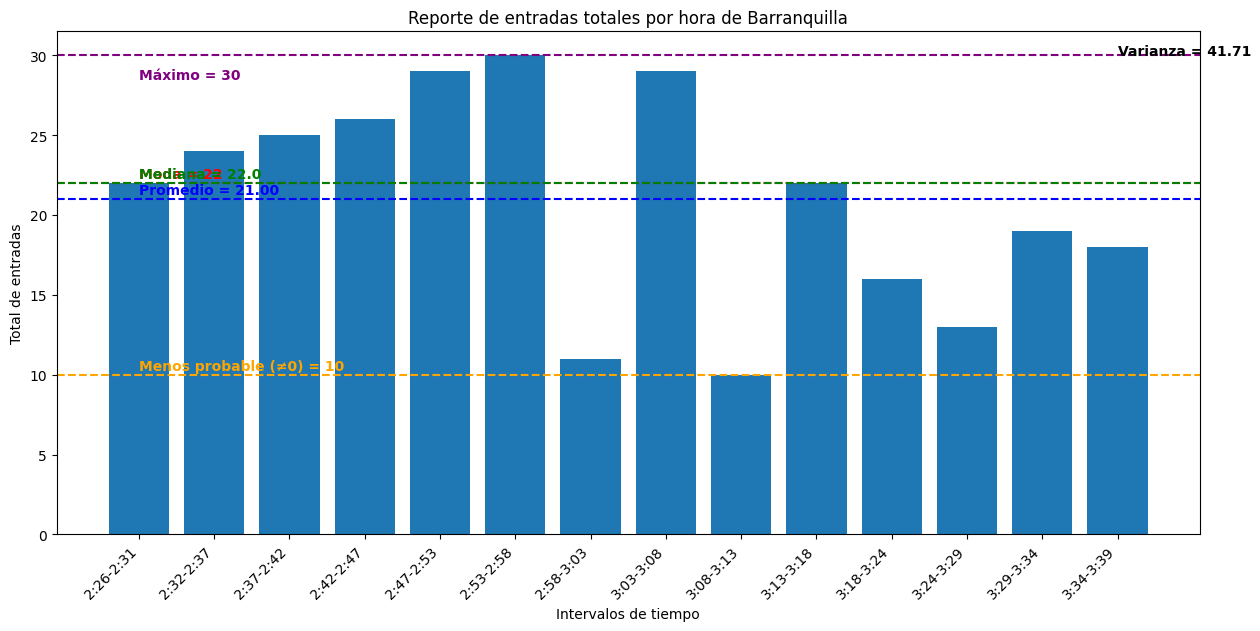

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,entrada_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entrada_total)

# ===== VARIANZA =====
valor_varianza = np.var(entrada_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entrada_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entrada_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entrada_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entrada_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entrada_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de entradas')
plt.title('Reporte de entradas totales por hora de Barranquilla')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

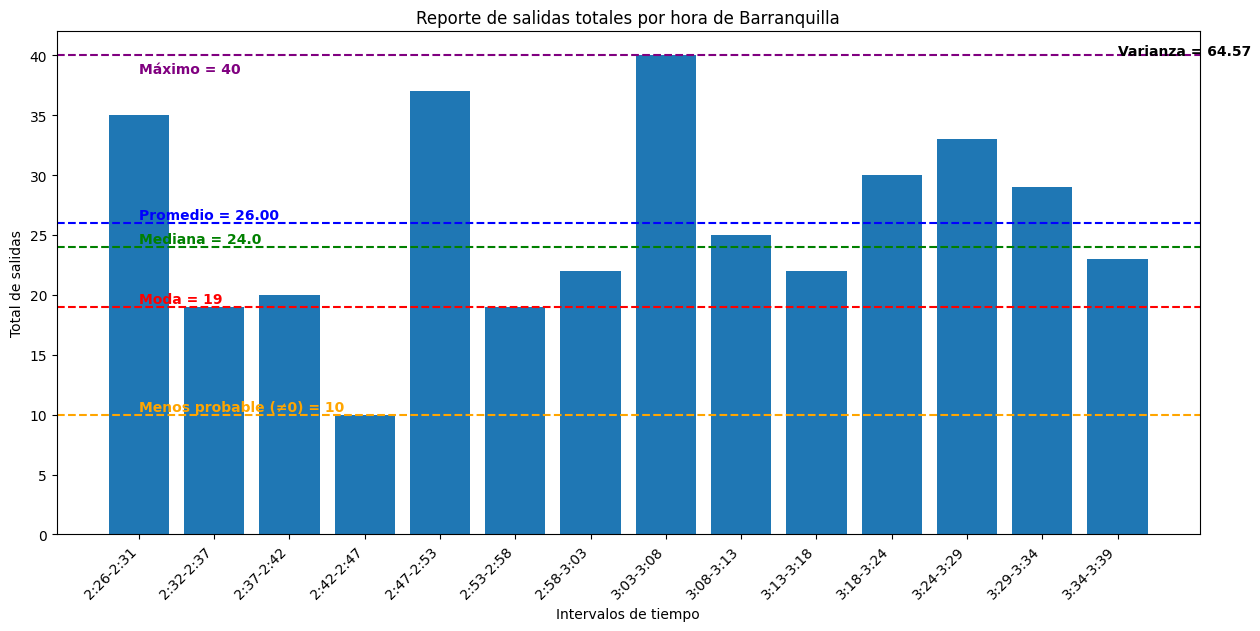

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,salida_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salida_total)

# ===== VARIANZA =====
valor_varianza = np.var(salida_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salida_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salida_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salida_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salida_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de salidas')
plt.title('Reporte de salidas totales por hora de Barranquilla')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

#Metro

In [ ]:
hora_inicio = [
    "2:33",
    "2:38",
    "2:43",
    "2:48",
    "2:53",
    "2:58",
    "3:03",
    "3:08",
    "3:13",
    "3:18",
    "3:23",
    "3:28",
    "3:33",
    "3:38"
]

hora_fin = [
    "2:38",
    "2:43",
    "2:48",
    "2:53",
    "2:58",
    "3:03",
    "3:08",
    "3:13",
    "3:18",
    "3:23",
    "3:28",
    "3:33",
    "3:38",
    "3:43"
]

entradas_hombres = [
    17, 15, 3, 21, 9, 16, 13,
    16, 11, 8, 17, 9, 17, 25
]

entradas_mujeres = [
    15, 22, 8, 8, 10, 18, 5,
    9, 9, 10, 15, 14, 18, 25
]

entradas_inter = [
    1, 0, 0, 1, 0, 0, 0,
    1, 0, 0, 0, 1, 1, 1
]

salidas_hombres = [
    20, 21, 24, 24, 12, 17, 14,
    30, 29, 25, 26, 27, 25, 32
]

salidas_mujeres = [
    24, 20, 12, 20, 12, 17, 31,
    20, 21, 29, 24, 28, 23, 26
]

salidas_inter = [
    1, 1, 0, 0, 0, 0, 0,
    0, 1, 0, 0, 0, 0, 0
]
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
entrada_total = []
salida_total = []
for i in range(len(entradas_hombres)):
  entrada_total.append(entradas_hombres[i]+entradas_mujeres[i]+entradas_inter[i])
  salida_total.append(salidas_hombres[i]+salidas_mujeres[i]+salidas_inter[i])

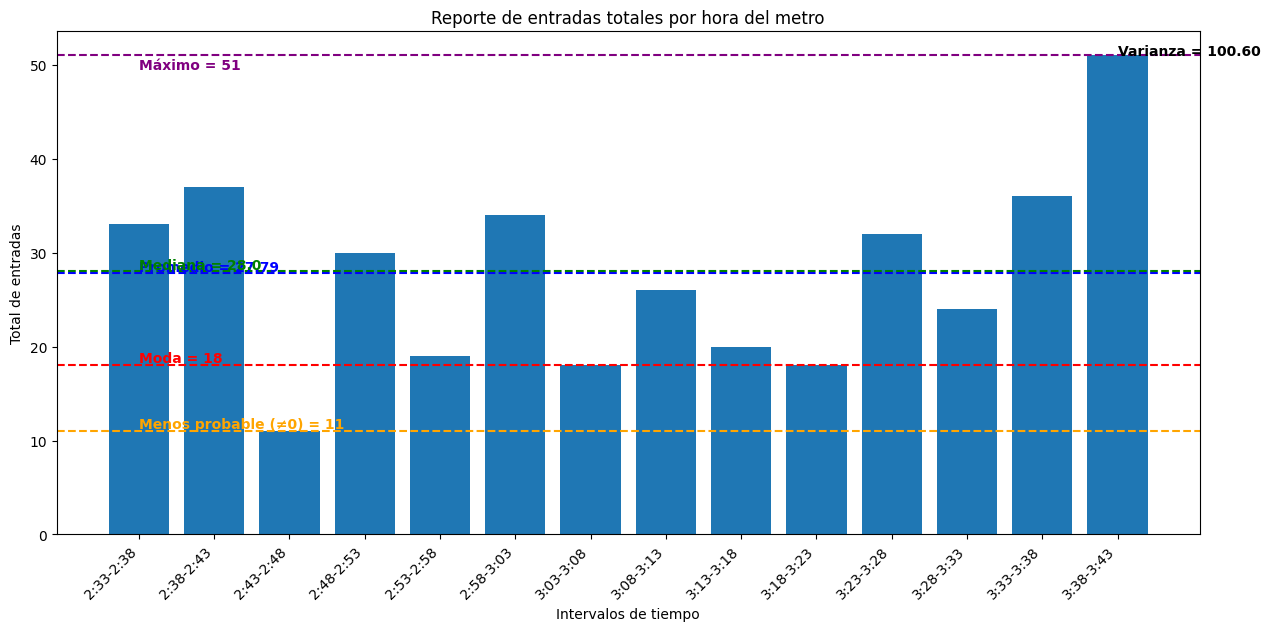

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,entrada_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entrada_total)

# ===== VARIANZA =====
valor_varianza = np.var(entrada_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entrada_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entrada_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entrada_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entrada_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entrada_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de entradas')
plt.title('Reporte de entradas totales por hora del metro')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

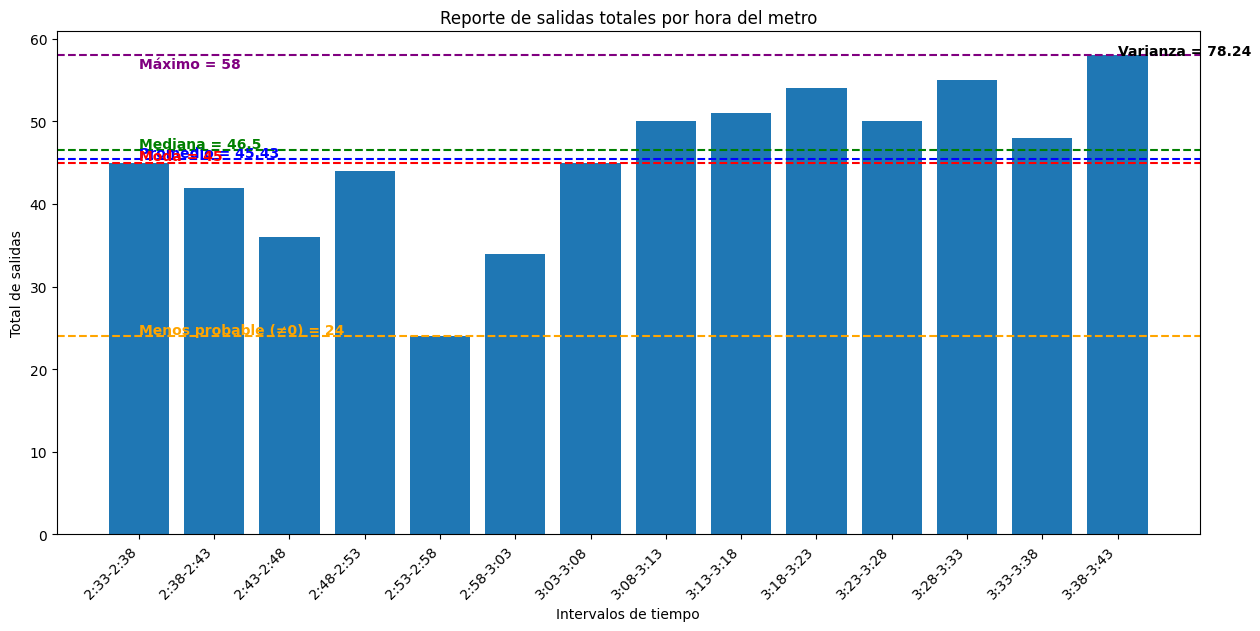

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,salida_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salida_total)

# ===== VARIANZA =====
valor_varianza = np.var(salida_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salida_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salida_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salida_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salida_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de salidas')
plt.title('Reporte de salidas totales por hora del metro')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

#Ferrocarril

In [ ]:
hora_inicio = [
    "2:25",
    "2:30",
    "2:36",
    "2:41",
    "2:48",
    "2:53",
    "2:58",
    "3:03",
    "3:08",
    "3:13",
    "3:19",
    "3:24",
    "3:29",
    "3:34"
]

hora_fin = [
    "2:30",
    "2:36",
    "2:41",
    "2:48",
    "2:53",
    "2:58",
    "3:03",
    "3:08",
    "3:13",
    "3:19",
    "3:24",
    "3:29",
    "3:34",
    "3:40"
]

entradas_hombres = [
    6, 15, 9, 13, 8, 12, 14,
    8, 8, 13, 9, 10, 10, 16
]

entradas_mujeres = [
    1, 9, 4, 4, 5, 4, 6,
    6, 6, 12, 2, 7, 9, 11
]

entradas_inter = [
    0, 0, 0, 0, 0, 0, 0,
    0, 1, 0, 0, 0, 0, 0
]

salidas_hombres = [
    1, 15, 11, 16, 4, 14, 12,
    11, 10, 21, 8, 19, 15, 20
]

salidas_mujeres = [
    4, 12, 6, 10, 7, 11, 3,
    4, 8, 8, 5, 6, 12, 9
]

salidas_inter = [
    0, 0, 0, 1, 0, 0, 0,
    0, 0, 0, 0, 0, 0, 0
]
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
entrada_total = []
salida_total = []
for i in range(len(entradas_hombres)):
  entrada_total.append(entradas_hombres[i]+entradas_mujeres[i]+entradas_inter[i])
  salida_total.append(salidas_hombres[i]+salidas_mujeres[i]+salidas_inter[i])

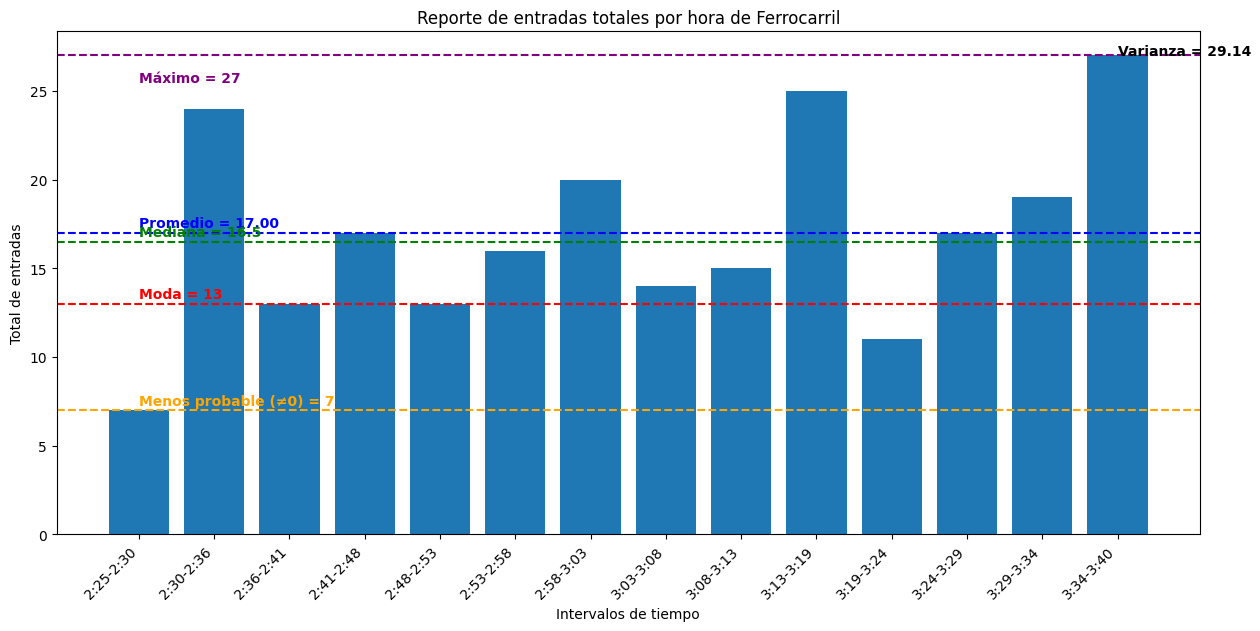

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,entrada_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entrada_total)

# ===== VARIANZA =====
valor_varianza = np.var(entrada_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entrada_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entrada_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entrada_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entrada_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entrada_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de entradas')
plt.title('Reporte de entradas totales por hora de Ferrocarril')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

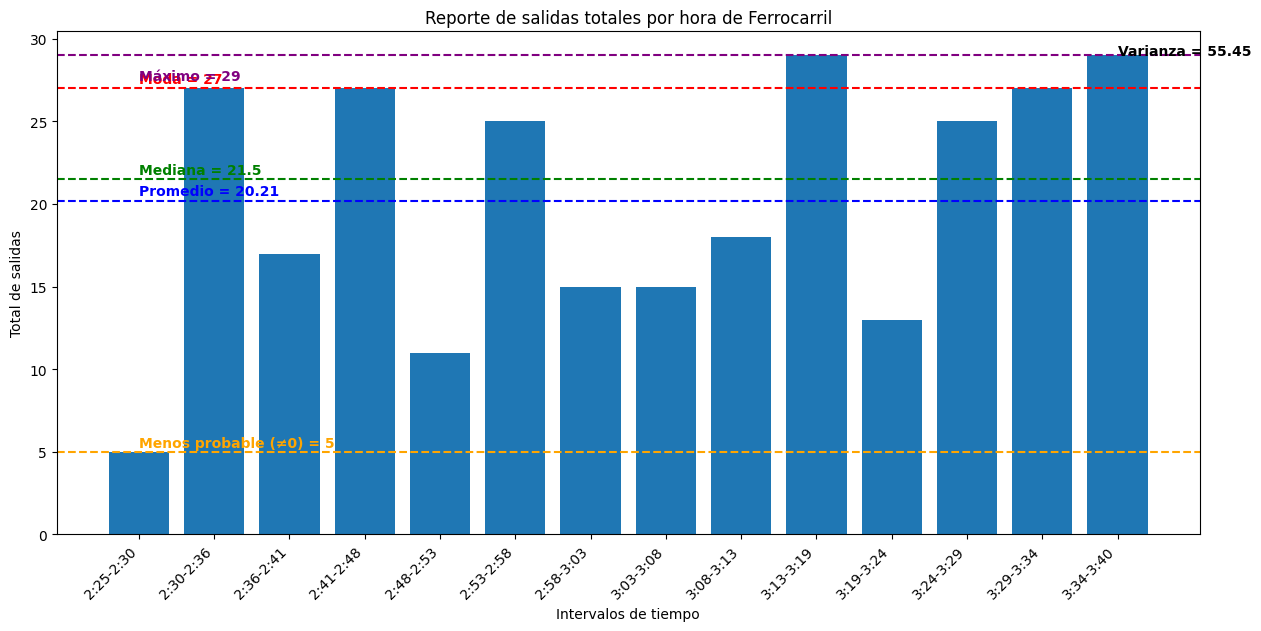

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,salida_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salida_total)

# ===== VARIANZA =====
valor_varianza = np.var(salida_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salida_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salida_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salida_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salida_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de salidas')
plt.title('Reporte de salidas totales por hora de Ferrocarril')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

#Barranquilla peatonal

In [ ]:
hora_inicio = [
    "2:27", "2:32", "2:37", "2:42", "2:47", "2:52",
    "2:57", "3:02", "3:07", "3:12", "3:17", "3:22", "3:27"
]

hora_fin = [
    "2:32", "2:37", "2:42", "2:47", "2:52", "2:57",
    "3:02", "3:07", "3:12", "3:17", "3:22", "3:27", "3:32"
]

entradas_hombres = [
    5, 9, 15, 19, 5, 2,
    11, 10, 10, 5, 11, 23, 23
]

entradas_mujeres = [
    7, 6, 3, 17, 3, 10,
    9, 10, 6, 3, 2, 22, 19
]

entradas_inter = [
    0, 1, 0, 1, 0, 0,
    0, 0, 0, 0, 0, 0, 0
]

salidas_hombres = [
    5, 8, 16, 6, 8, 5,
    6, 10, 11, 8, 6, 16, 11
]

salidas_mujeres = [
    15, 13, 16, 5, 3, 6,
    5, 15, 3, 8, 10, 10, 5
]

salidas_inter = [
    0, 0, 1, 1, 0, 0,
    0, 1, 0, 0, 0, 0, 1
]
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
entrada_total = []
salida_total = []
for i in range(len(entradas_hombres)):
  entrada_total.append(entradas_hombres[i]+entradas_mujeres[i]+entradas_inter[i])
  salida_total.append(salidas_hombres[i]+salidas_mujeres[i]+salidas_inter[i])

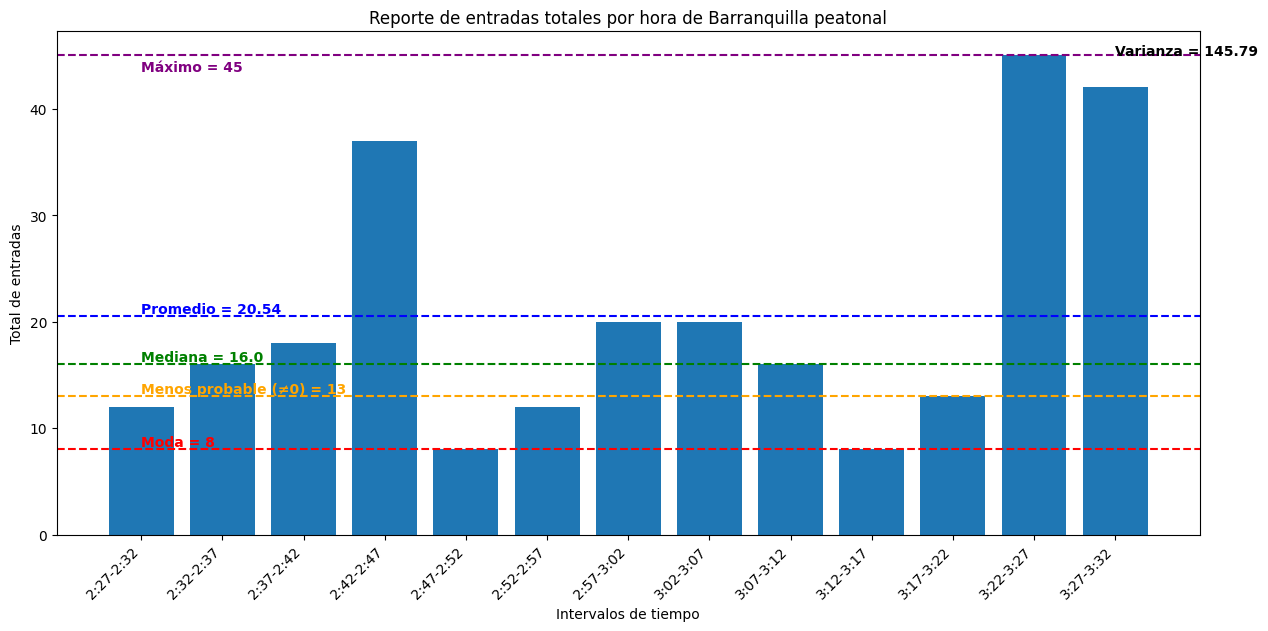

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,entrada_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entrada_total)

# ===== VARIANZA =====
valor_varianza = np.var(entrada_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entrada_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entrada_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entrada_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entrada_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entrada_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de entradas')
plt.title('Reporte de entradas totales por hora de Barranquilla peatonal')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

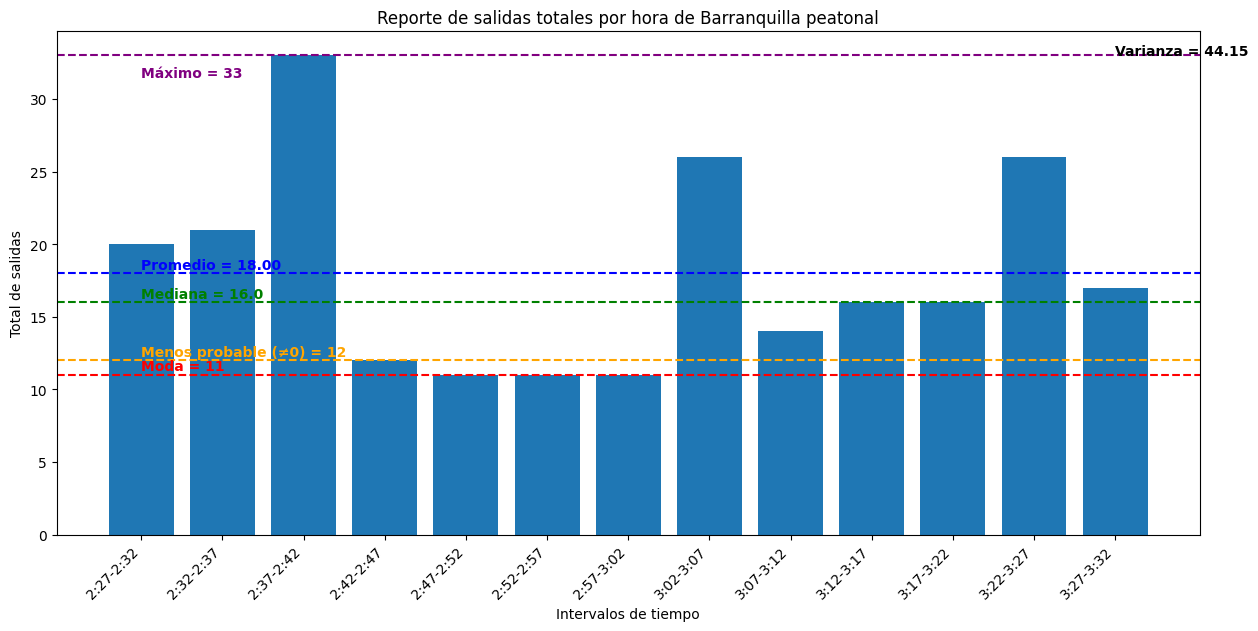

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,salida_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salida_total)

# ===== VARIANZA =====
valor_varianza = np.var(salida_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salida_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salida_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salida_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salida_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')


plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de salidas')
plt.title('Reporte de salidas totales por hora de Barranquilla peatonal')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

#Museo

In [ ]:
hora_inicio = [
    "2:30", "2:35", "2:40", "2:45", "2:50", "2:55",
    "3:00", "3:05", "3:10", "3:15", "3:20", "3:25",
    "3:30", "3:35"
]

hora_fin = [
    "2:35", "2:40", "2:45", "2:50", "2:55", "3:00",
    "3:05", "3:10", "3:15", "3:20", "3:25", "3:30",
    "3:35", "3:40"
]

entradas_hombres = [
    2, 5, 1, 2, 1, 5,
    2, 1, 4, 1, 4, 0,
    0, 3
]

entradas_mujeres = [
    5, 6, 1, 1, 6, 0,
    2, 3, 1, 2, 5, 3,
    1, 3
]

entradas_inter = [
    0, 0, 1, 0, 1, 0,
    0, 0, 1, 0, 0, 0,
    0, 0
]

salidas_hombres = [
    3, 3, 3, 1, 5, 4,
    6, 1, 2, 2, 2, 2,
    0, 7
]

salidas_mujeres = [
    3, 6, 5, 1, 3, 2,
    5, 1, 0, 2, 4, 2,
    2, 27
]

salidas_inter = [
    0, 0, 1, 0, 0, 0,
    1, 0, 0, 0, 1, 0,
    0, 0
]
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
entrada_total = []
salida_total = []
for i in range(len(entradas_hombres)):
  entrada_total.append(entradas_hombres[i]+entradas_mujeres[i]+entradas_inter[i])
  salida_total.append(salidas_hombres[i]+salidas_mujeres[i]+salidas_inter[i])

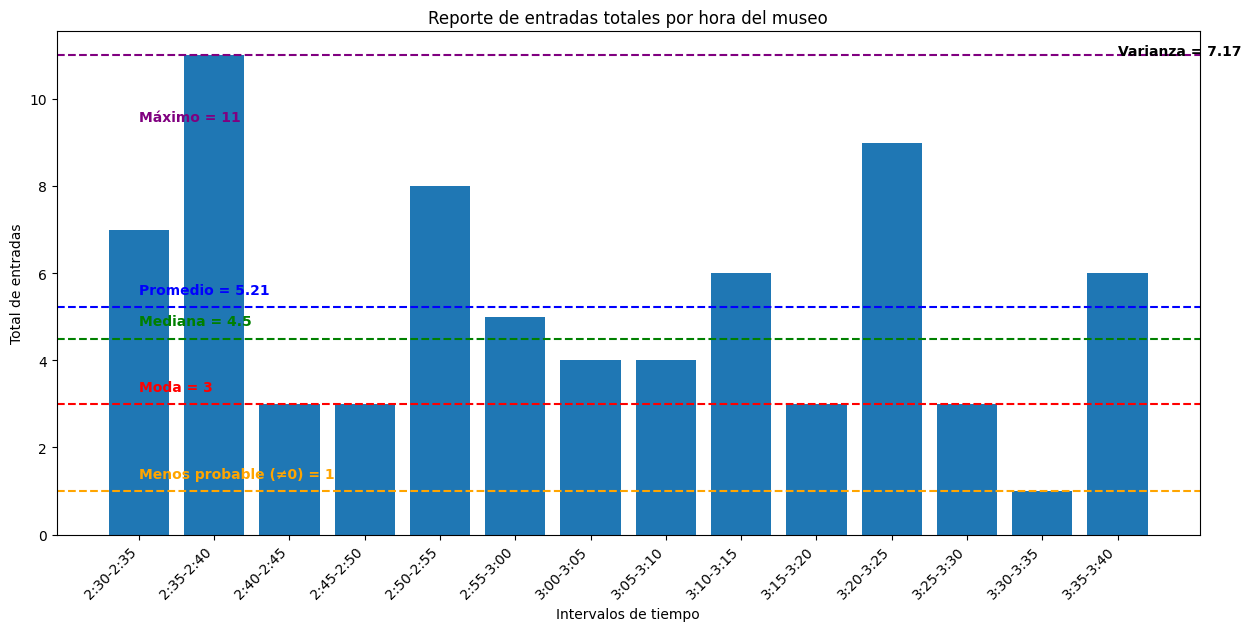

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,entrada_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entrada_total)

# ===== VARIANZA =====
valor_varianza = np.var(entrada_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entrada_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entrada_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entrada_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entrada_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entrada_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de entradas')
plt.title('Reporte de entradas totales por hora del museo')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

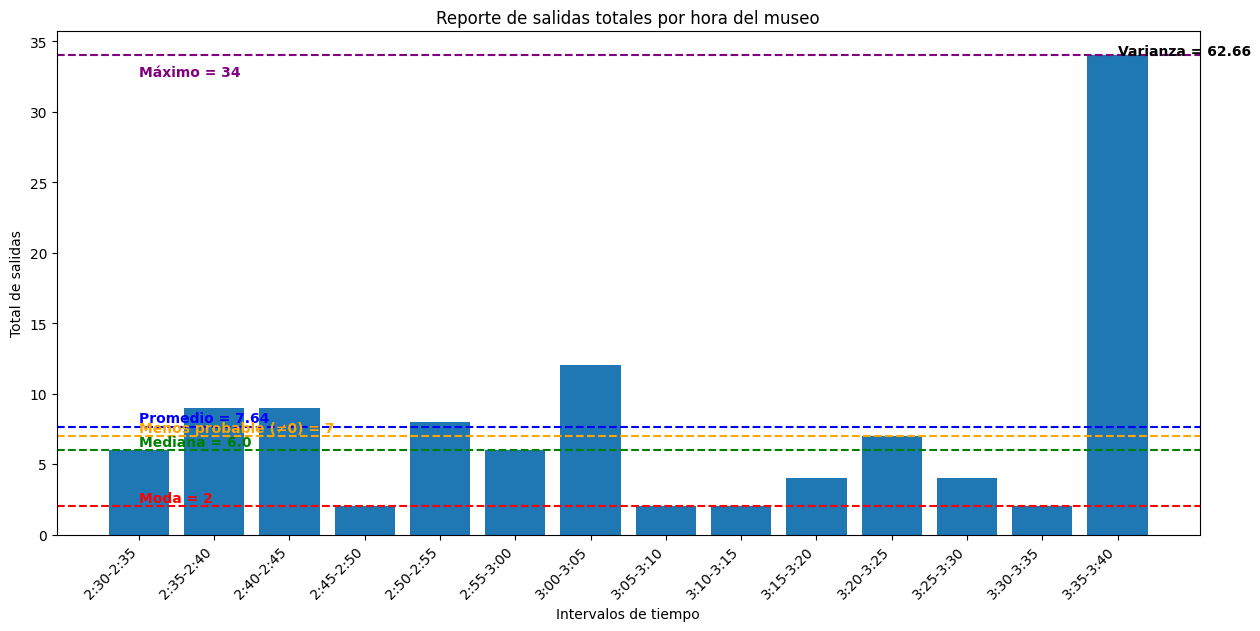

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(intervalos,salida_total)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salida_total)

# ===== VARIANZA =====
valor_varianza = np.var(salida_total)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salida_total),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salida_total)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salida_total)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salida_total)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salida_total, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Total de salidas')
plt.title('Reporte de salidas totales por hora del museo')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

#Bibliteca discriminativo

In [ ]:
hora_inicio = [
    "2:29:00",
    "2:35:00",
    "2:41:00",
    "2:47:00",
    "2:53:00",
    "2:59:00",
    "3:05:00",
    "3:11:00",
    "3:17:00",
    "3:22:30",
    "3:28:00",
    "3:33:30"
]

hora_fin = [
    "2:34:00",
    "2:40:00",
    "2:46:00",
    "2:52:00",
    "2:58:00",
    "3:04:00",
    "3:10:00",
    "3:16:00",
    "3:22:00",
    "3:27:30",
    "3:33:00",
    "3:38:30"
]

entradas_hombres = [
    19, 17, 9, 17, 14, 23,
    31, 17, 16, 17, 26, 16
]

entradas_mujeres = [
    13, 13, 11, 13, 20, 18,
    19, 19, 13, 11, 8, 15
]

entradas_inter = [
    0, 0, 0, 0, 0, 0,
    1, 0, 0, 0, 0, 0
]

salidas_hombres = [
    10, 9, 6, 6, 8, 20,
    16, 15, 15, 15, 25, 24
]

salidas_mujeres = [
    8, 8, 6, 9, 12, 13,
    7, 16, 16, 7, 12, 9
]

salidas_inter = [
    0, 0, 0, 0, 0, 0,
    1, 0, 0, 0, 0, 2
]

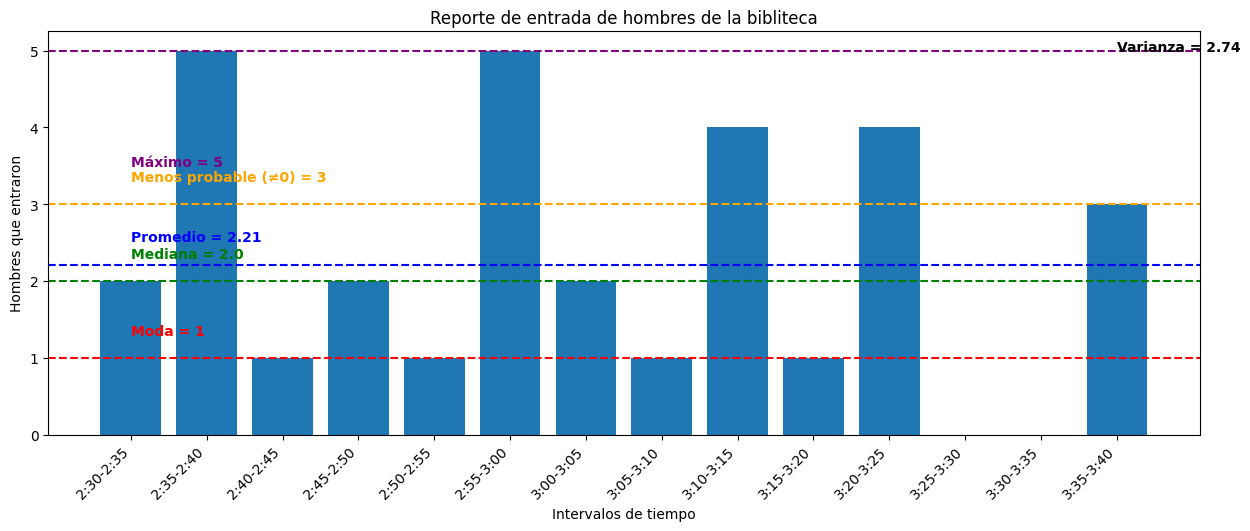

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

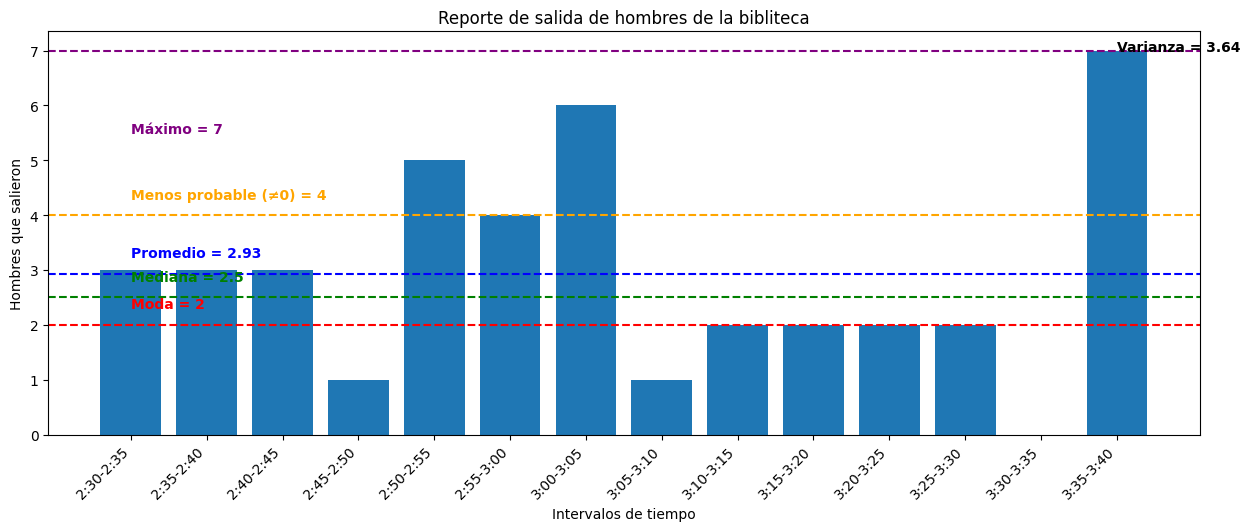

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

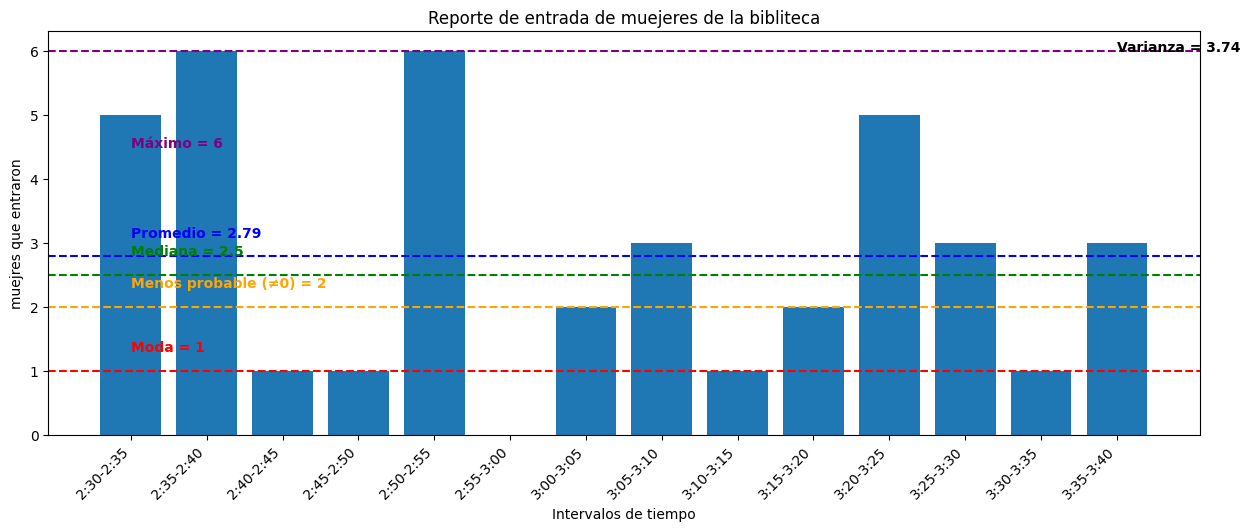

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

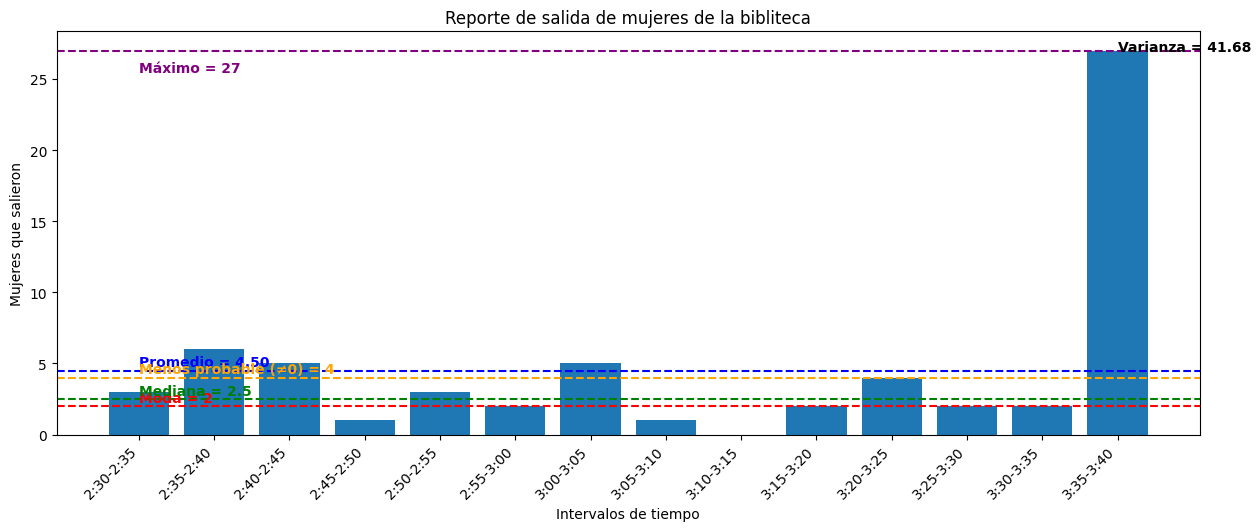

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

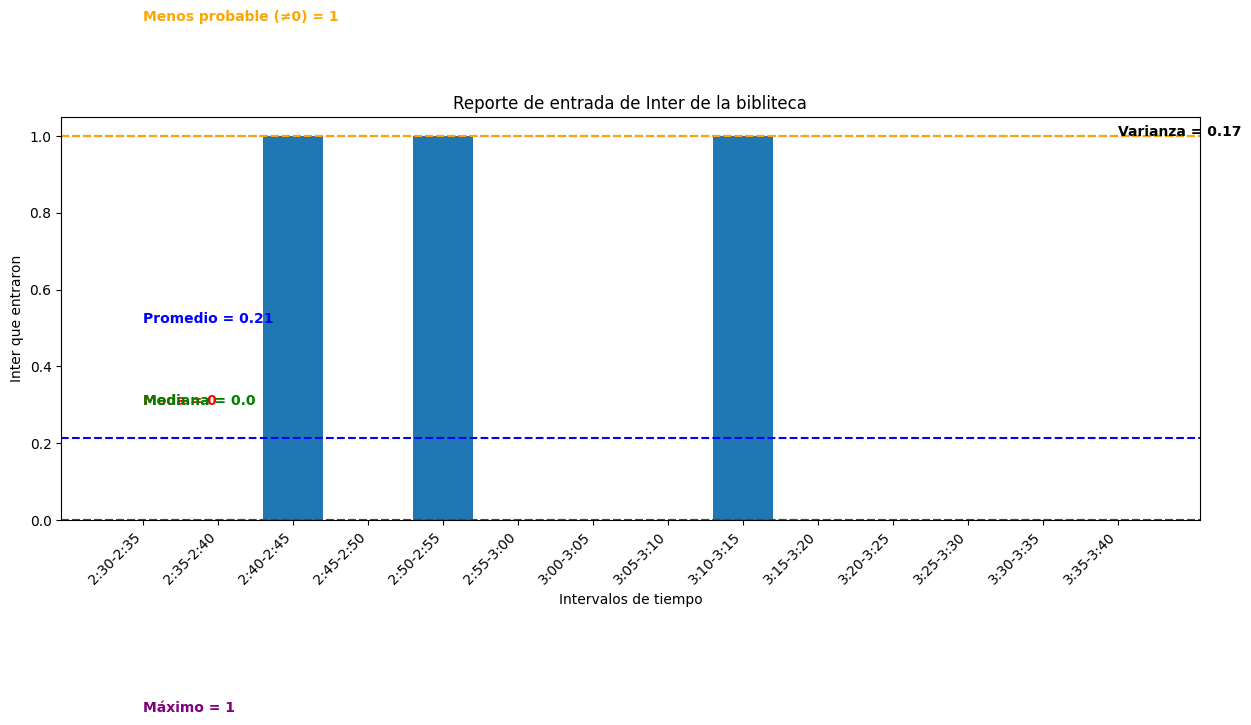

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

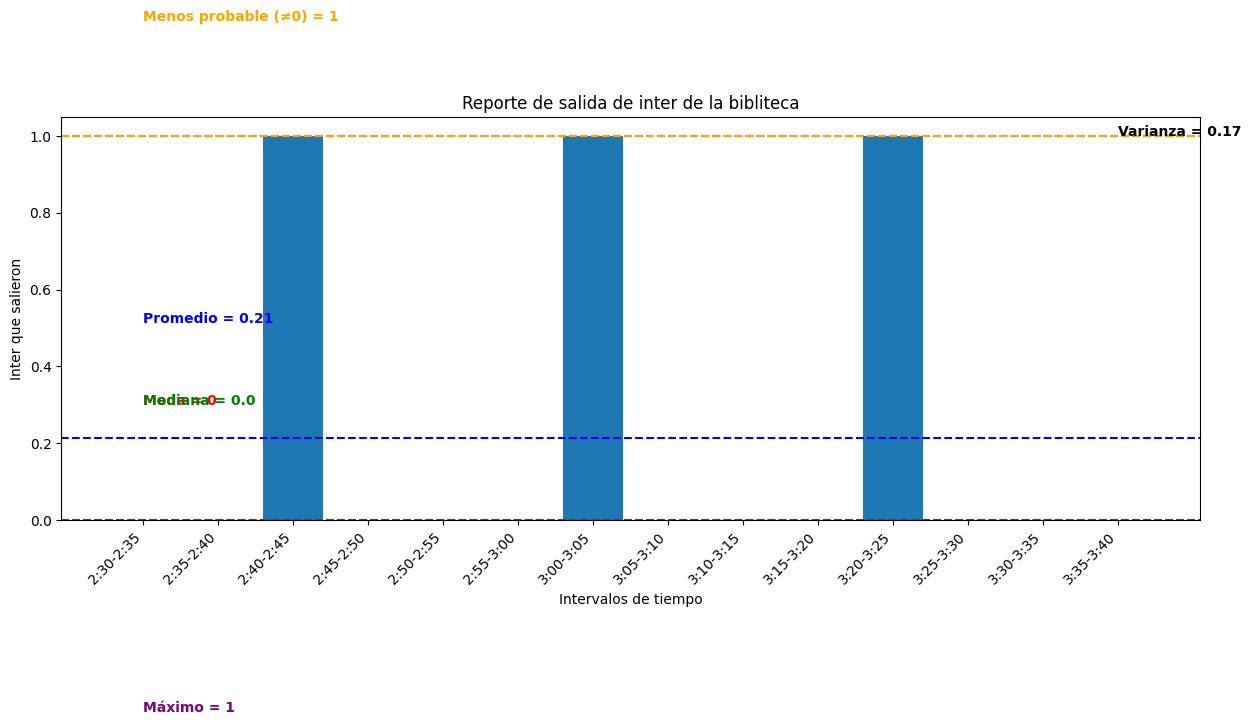

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]
plt.figure(figsize=(12, 5))
plt.bar(intervalos,entradas_hombres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entradas_hombres)

# ===== VARIANZA =====
valor_varianza = np.var(entradas_hombres)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entradas_hombres),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entradas_hombres)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entradas_hombres)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entradas_hombres)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entradas_hombres, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Hombres que entraron')
plt.title('Reporte de entrada de hombres de la bibliteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")
plt.figure(figsize=(12, 5))
plt.bar(intervalos,salidas_hombres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salidas_hombres)

# ===== VARIANZA =====
valor_varianza = np.var(salidas_hombres)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salidas_hombres),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salidas_hombres)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salidas_hombres)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salidas_hombres)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salidas_hombres, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Hombres que salieron')
plt.title('Reporte de salida de hombres de la bibliteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")
plt.figure(figsize=(12, 5))
plt.bar(intervalos,entradas_mujeres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entradas_mujeres)

# ===== VARIANZA =====
valor_varianza = np.var(entradas_mujeres)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entradas_mujeres),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entradas_mujeres)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entradas_mujeres)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entradas_mujeres)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entradas_mujeres, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('muejres que entraron')
plt.title('Reporte de entrada de muejeres de la bibliteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")
plt.figure(figsize=(12, 5))
plt.bar(intervalos,salidas_mujeres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salidas_mujeres)

# ===== VARIANZA =====
valor_varianza = np.var(salidas_mujeres)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salidas_mujeres),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salidas_mujeres)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salidas_mujeres)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salidas_mujeres)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salidas_mujeres, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Mujeres que salieron')
plt.title('Reporte de salida de mujeres de la bibliteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")
plt.figure(figsize=(12, 5))
plt.bar(intervalos,entradas_inter)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(entradas_inter)

# ===== VARIANZA =====
valor_varianza = np.var(entradas_inter)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(entradas_inter),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(entradas_inter)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(entradas_inter)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(entradas_inter)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(entradas_inter, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Inter que entraron')
plt.title('Reporte de entrada de Inter de la bibliteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")
plt.figure(figsize=(12, 5))
plt.bar(intervalos,salidas_inter)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# ===== PROMEDIO =====
valor_promedio = np.mean(salidas_inter)

# ===== VARIANZA =====
valor_varianza = np.var(salidas_inter)
plt.axhline(valor_promedio,
            color='blue',
            linestyle='--',
            label=f'Promedio = {valor_promedio:.2f}')

# Texto del promedio
plt.text(0,
         valor_promedio + 0.3,
         f'Promedio = {valor_promedio:.2f}',
         color='blue',
         fontweight='bold')

# Texto de la varianza
plt.text(len(intervalos)-1,
         max(salidas_inter),
         f'Varianza = {valor_varianza:.2f}',
         color='black',
         fontweight='bold')
res_moda = stats.mode(salidas_inter)

# 2. Extraer el valor numérico limpio (manera segura para cualquier versión de SciPy)
valor_moda = np.asarray(res_moda.mode).item()

# 3. Graficar la línea y el texto usando el número limpio
plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

valor_mediana = np.median(salidas_inter)

# 2. Graficar la línea horizontal y el texto de la mediana
plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

valor_maximo = np.max(salidas_inter)

# 2. Graficar la línea horizontal y el texto del máximo
plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
# Restamos un poco en el eje Y (valor_maximo - 1.5) para que el texto no quede cortado arriba
plt.text(0, valor_maximo - 1.5, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

valores, conteos = np.unique(salidas_inter, return_counts=True)

# 2. Filtrar para excluir el cero
mascara_sin_cero = (valores != 0)
valores_sin_cero = valores[mascara_sin_cero]
conteos_sin_cero = conteos[mascara_sin_cero]

# 3. Encontrar el valor con la menor frecuencia (menos probable)
# Si hay empate, toma el primero que encuentra
indice_menos_probable = np.argmin(conteos_sin_cero)
valor_menos_probable = valores_sin_cero[indice_menos_probable]

plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable (≠0): {valor_menos_probable}')
plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

plt.xlabel('Intervalos de tiempo')
plt.ylabel('Inter que salieron')
plt.title('Reporte de salida de inter de la bibliteca')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")                                                          # 2. mostrar

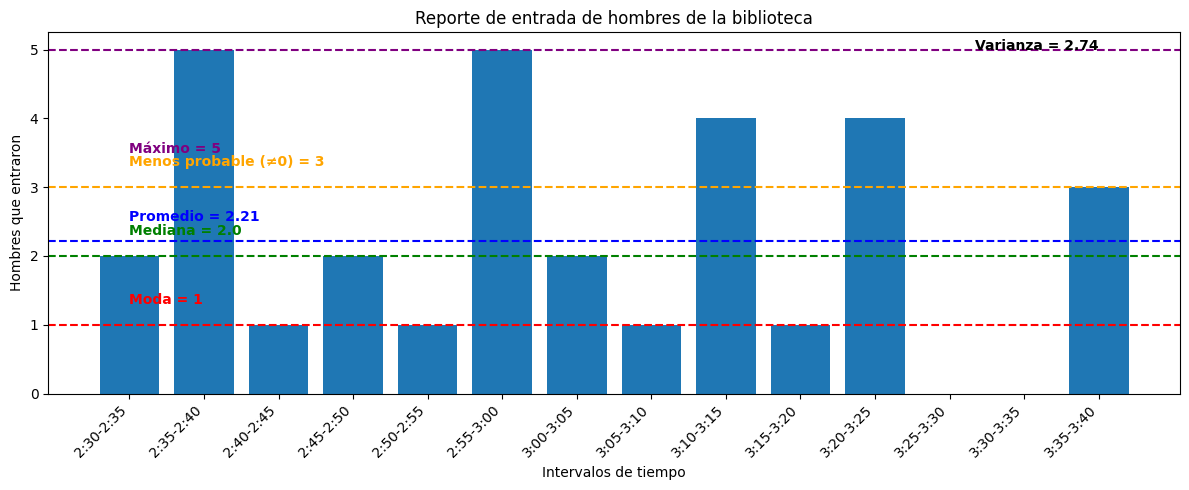

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

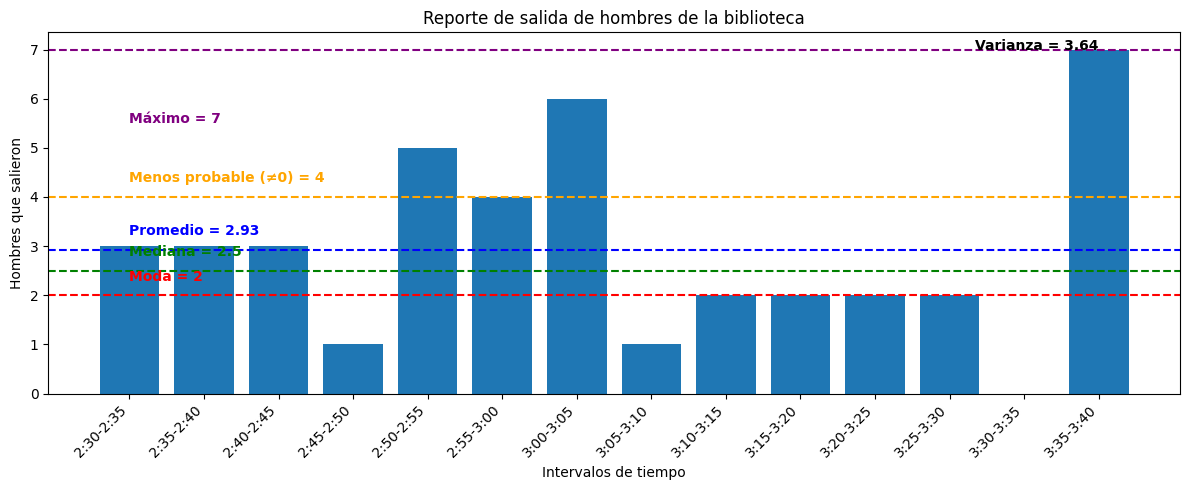

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

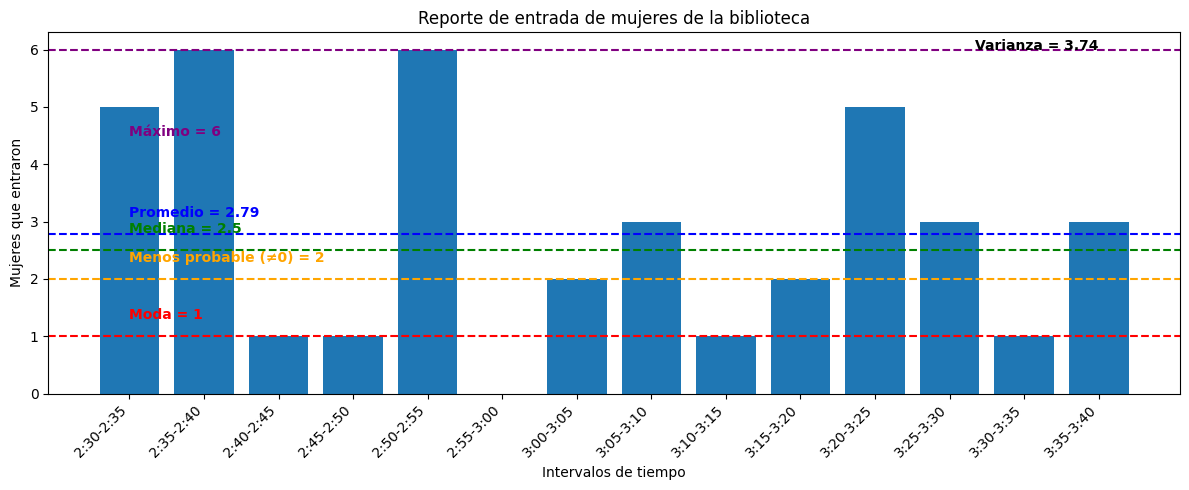

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

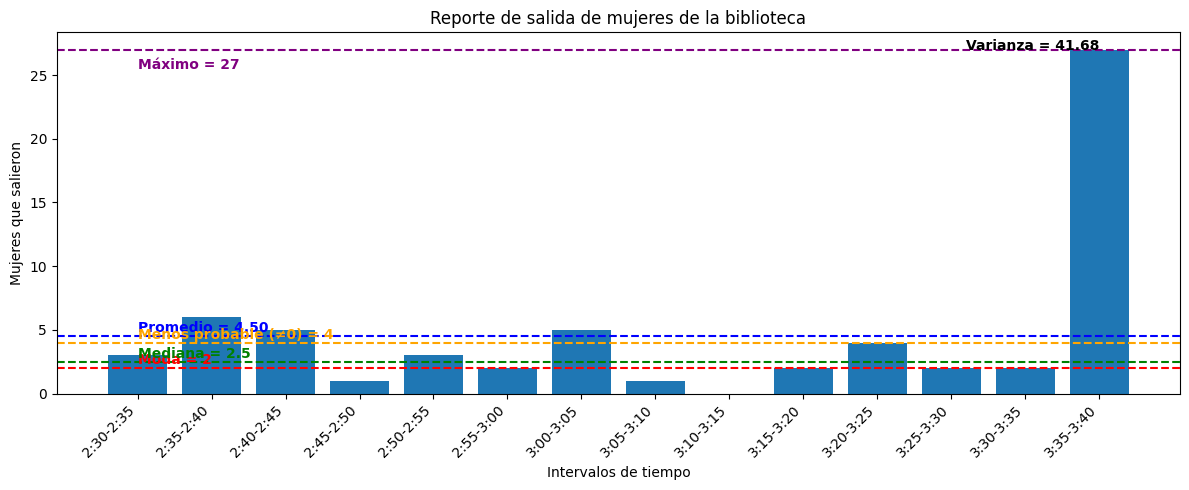

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

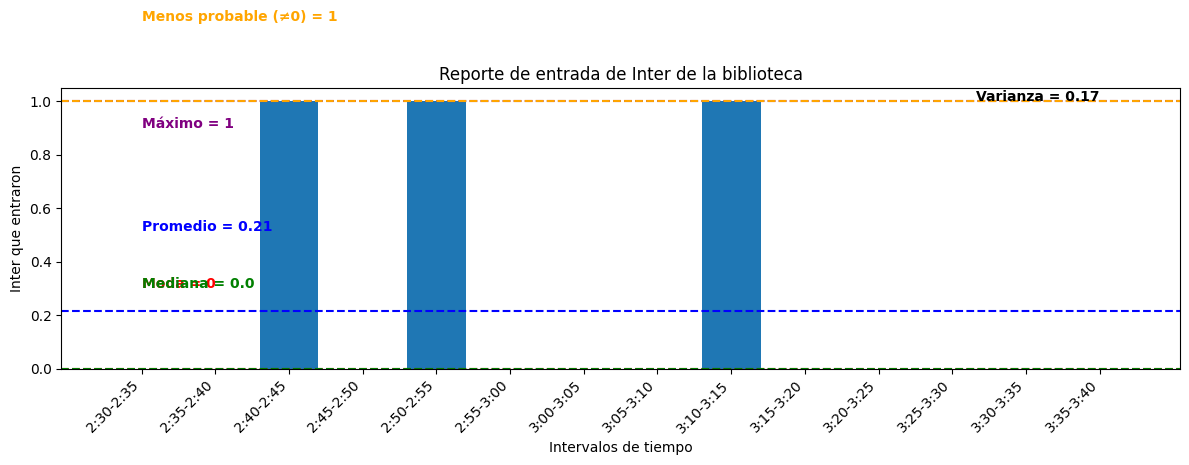

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

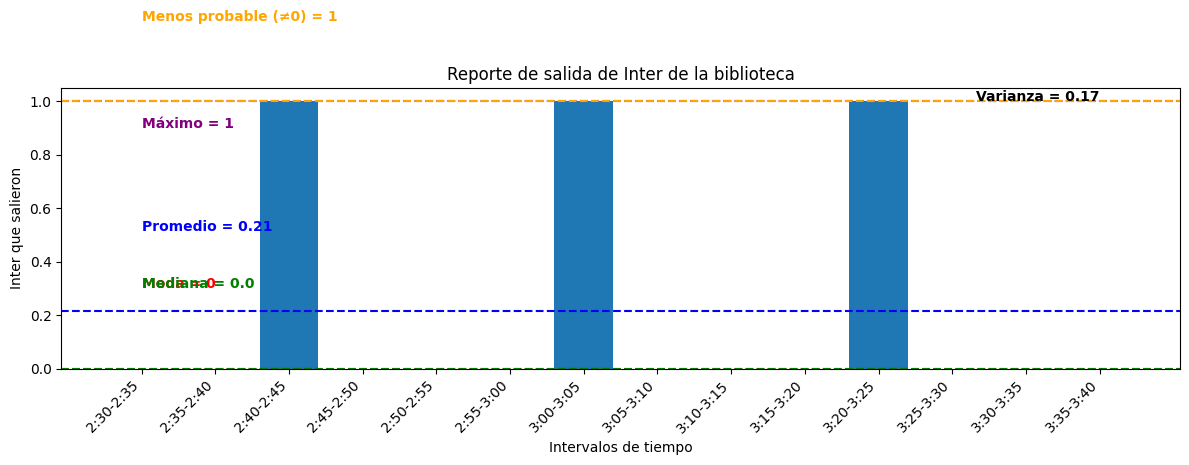

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

# 1. Crear los intervalos de tiempo una sola vez
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio, hora_fin)]

# =====================================================================
# FUNCIÓN MAESTRA PARA GENERAR, GUARDAR Y DESCARGAR EL REPORTE
# =====================================================================
def generar_reporte(datos, titulo, eje_y, nombre_archivo):
    plt.figure(figsize=(12, 5))
    plt.bar(intervalos, datos)
    plt.xticks(rotation=45, ha='right')

    # ----- CÁLCULOS ESTADÍSTICOS -----
    valor_promedio = np.mean(datos)
    valor_varianza = np.var(datos)
    valor_mediana = np.median(datos)
    valor_maximo = np.max(datos)

    # Moda (segura para cualquier versión de SciPy)
    res_moda = stats.mode(datos)
    valor_moda = np.asarray(res_moda.mode).item()

    # Menos probable (excluyendo el cero)
    valores, conteos = np.unique(datos, return_counts=True)
    mascara_sin_cero = (valores != 0)
    if np.any(mascara_sin_cero):  # Evita errores si todo el array es cero
        valores_sin_cero = valores[mascara_sin_cero]
        conteos_sin_cero = conteos[mascara_sin_cero]
        valor_menos_probable = valores_sin_cero[np.argmin(conteos_sin_cero)]
    else:
        valor_menos_probable = 0

    # ----- GRAFICAR LÍNEAS Y TEXTOS -----
    # Promedio
    plt.axhline(valor_promedio, color='blue', linestyle='--', label=f'Promedio: {valor_promedio:.2f}')
    plt.text(0, valor_promedio + 0.3, f'Promedio = {valor_promedio:.2f}', color='blue', fontweight='bold')

    # Varianza (Texto arriba a la derecha)
    plt.text(len(intervalos)-1, max(datos), f'Varianza = {valor_varianza:.2f}', color='black', fontweight='bold', ha='right')

    # Moda
    plt.axhline(valor_moda, color='red', linestyle='--', label=f'Moda: {valor_moda}')
    plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

    # Mediana
    plt.axhline(valor_mediana, color='green', linestyle='--', label=f'Mediana: {valor_mediana}')
    plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

    # Máximo
    plt.axhline(valor_maximo, color='purple', linestyle='--', label=f'Máximo: {valor_maximo}')
    plt.text(0, valor_maximo - 1.5 if valor_maximo > 1.5 else valor_maximo * 0.9, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

    # Menos probable
    if valor_menos_probable != 0:
        plt.axhline(valor_menos_probable, color='orange', linestyle='--', label=f'Menos probable: {valor_menos_probable}')
        plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

    # ----- DETALLES FINALES Y EXPORTACIÓN -----
    plt.xlabel('Intervalos de tiempo')
    plt.ylabel(eje_y)
    plt.title(titulo)
    plt.tight_layout()

    # Guardar, mostrar y descargar con nombre único
    plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()
    files.download(nombre_archivo)
    plt.close() # Cierra la figura actual para liberar memoria

# =====================================================================
# EJECUCIÓN DE LOS 6 REPORTES
# =====================================================================

# 1. Hombres - Entradas
generar_reporte(entradas_hombres, 'Reporte de entrada de hombres de la biblioteca', 'Hombres que entraron', 'reporte_entradas_hombres.png')

# 2. Hombres - Salidas
generar_reporte(salidas_hombres, 'Reporte de salida de hombres de la biblioteca', 'Hombres que salieron', 'reporte_salidas_hombres.png')

# 3. Mujeres - Entradas
generar_reporte(entradas_mujeres, 'Reporte de entrada de mujeres de la biblioteca', 'Mujeres que entraron', 'reporte_entradas_mujeres.png')

# 4. Mujeres - Salidas
generar_reporte(salidas_mujeres, 'Reporte de salida de mujeres de la biblioteca', 'Mujeres que salieron', 'reporte_salidas_mujeres.png')

# 5. Inter - Entradas
generar_reporte(entradas_inter, 'Reporte de entrada de Inter de la biblioteca', 'Inter que entraron', 'reporte_entradas_inter.png')

# 6. Inter - Salidas
generar_reporte(salidas_inter, 'Reporte de salida de Inter de la biblioteca', 'Inter que salieron', 'reporte_salidas_inter.png')

#Museo discriminativo

In [ ]:
hora_inicio = [
    "2:30", "2:35", "2:40", "2:45", "2:50", "2:55",
    "3:00", "3:05", "3:10", "3:15", "3:20", "3:25",
    "3:30", "3:35"
]

hora_fin = [
    "2:35", "2:40", "2:45", "2:50", "2:55", "3:00",
    "3:05", "3:10", "3:15", "3:20", "3:25", "3:30",
    "3:35", "3:40"
]

entradas_hombres = [
    2, 5, 1, 2, 1, 5,
    2, 1, 4, 1, 4, 0,
    0, 3
]

entradas_mujeres = [
    5, 6, 1, 1, 6, 0,
    2, 3, 1, 2, 5, 3,
    1, 3
]

entradas_inter = [
    0, 0, 1, 0, 1, 0,
    0, 0, 1, 0, 0, 0,
    0, 0
]

salidas_hombres = [
    3, 3, 3, 1, 5, 4,
    6, 1, 2, 2, 2, 2,
    0, 7
]

salidas_mujeres = [
    3, 6, 5, 1, 3, 2,
    5, 1, 0, 2, 4, 2,
    2, 27
]

salidas_inter = [
    0, 0, 1, 0, 0, 0,
    1, 0, 0, 0, 1, 0,
    0, 0
]
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio,hora_fin)]

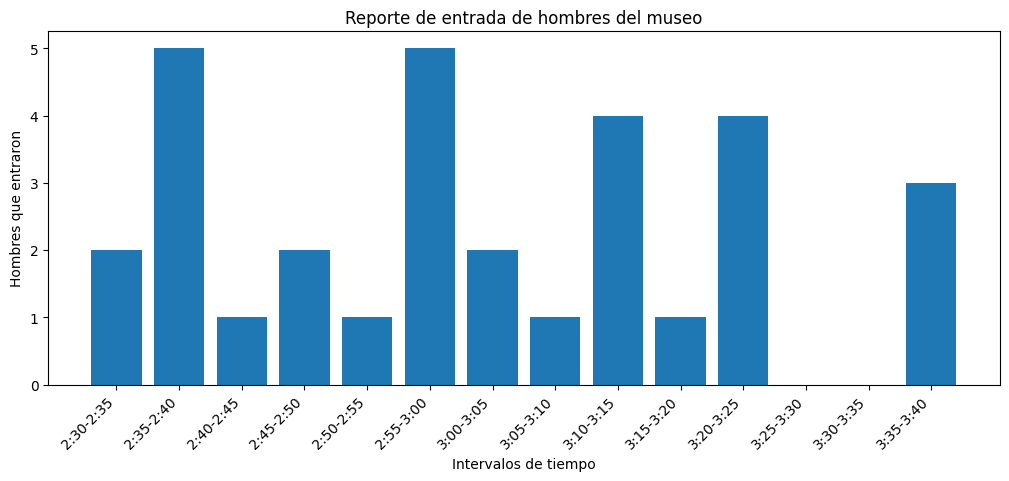

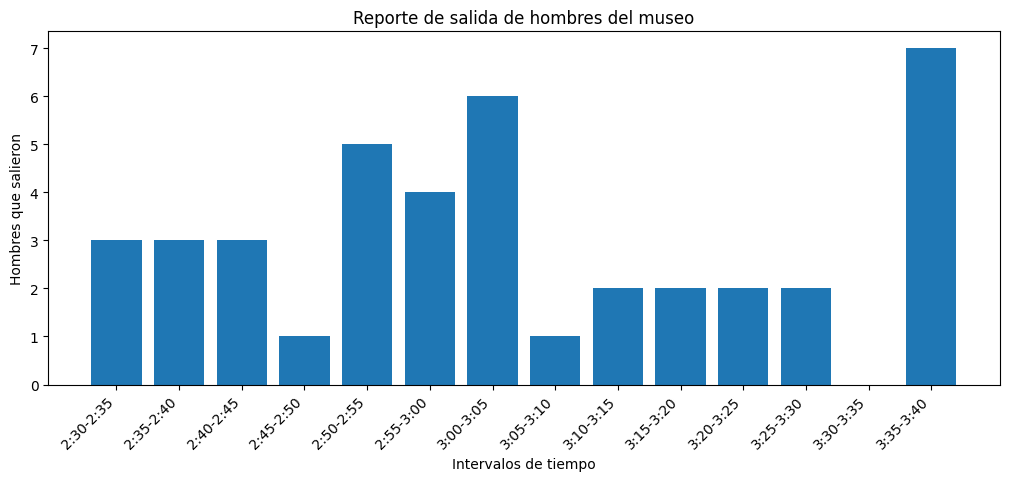

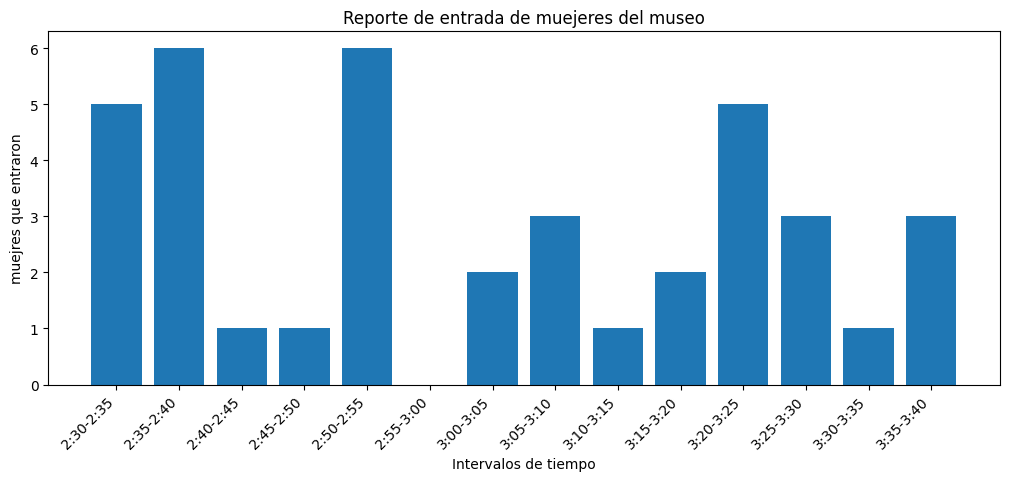

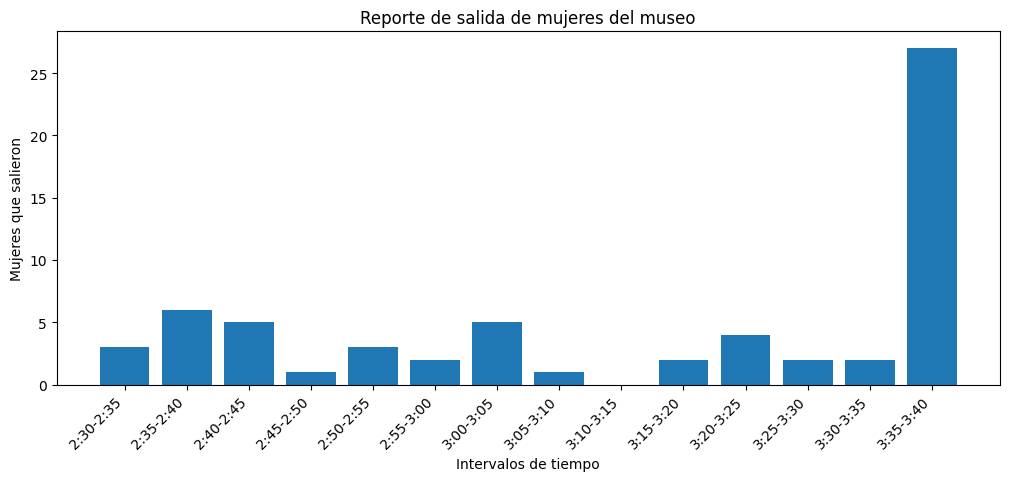

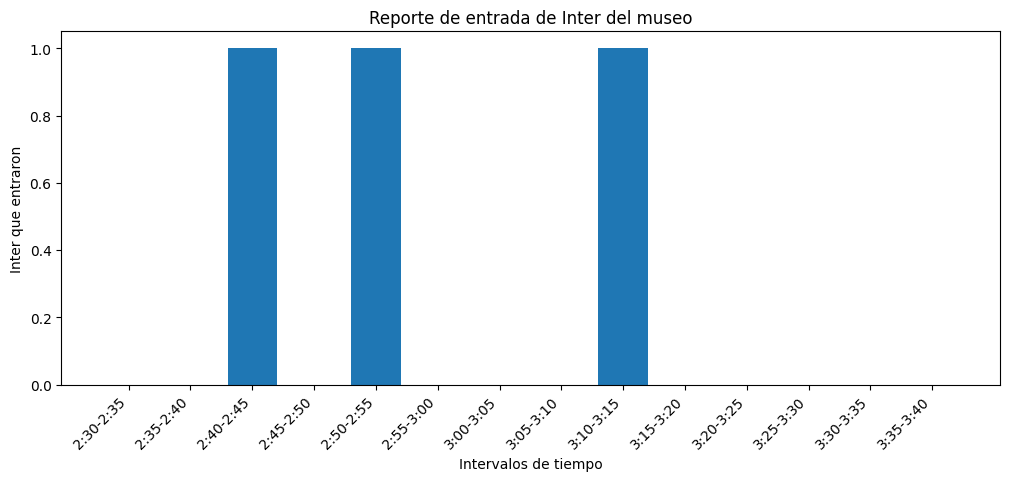

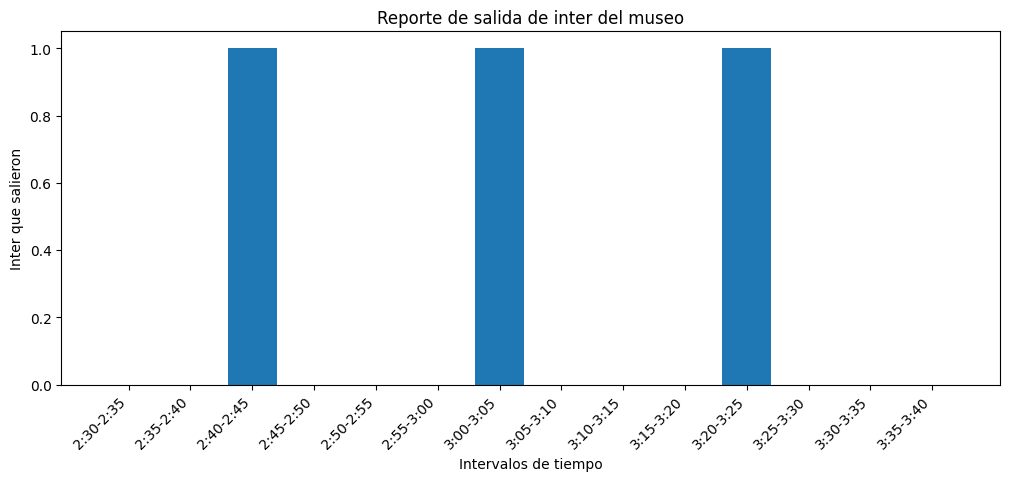

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(10, 4.5))
plt.bar(intervalos,entradas_hombres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xlabel('Intervalos de tiempo')
plt.ylabel('Hombres que entraron')
plt.title('Reporte de entrada de hombres del museo')
plt.show()
plt.figure(figsize=(10, 4.5))
plt.bar(intervalos,salidas_hombres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xlabel('Intervalos de tiempo')
plt.ylabel('Hombres que salieron')
plt.title('Reporte de salida de hombres del museo')
plt.show()
plt.figure(figsize=(10, 4.5))
plt.bar(intervalos,entradas_mujeres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xlabel('Intervalos de tiempo')
plt.ylabel('muejres que entraron')
plt.title('Reporte de entrada de muejeres del museo')
plt.show()
plt.figure(figsize=(10, 4.5))
plt.bar(intervalos,salidas_mujeres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xlabel('Intervalos de tiempo')
plt.ylabel('Mujeres que salieron')
plt.title('Reporte de salida de mujeres del museo')
plt.show()
plt.figure(figsize=(10, 4.5))
plt.bar(intervalos,entradas_inter)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xlabel('Intervalos de tiempo')
plt.ylabel('Inter que entraron')
plt.title('Reporte de entrada de Inter del museo')
plt.show()
plt.figure(figsize=(10, 4.5))
plt.bar(intervalos,salidas_inter)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xlabel('Intervalos de tiempo')
plt.ylabel('Inter que salieron')
plt.title('Reporte de salida de inter del museo')
plt.savefig("grafica.png", dpi=300, bbox_inches="tight")  # 1. guardar
plt.show()                                                 # 2. mostrar

from google.colab import files
files.download("grafica.png")

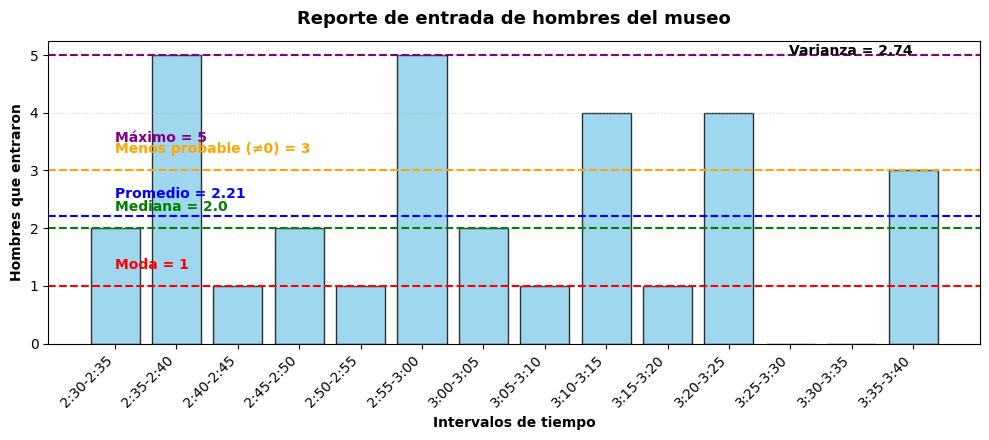

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

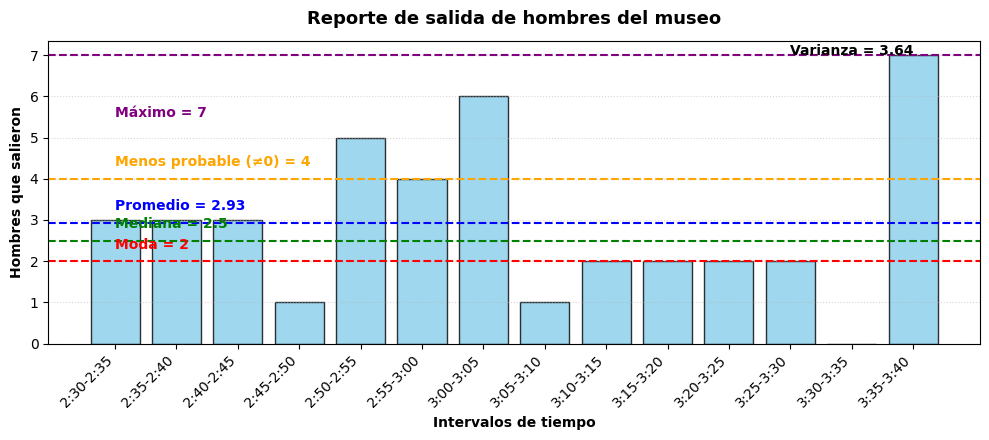

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

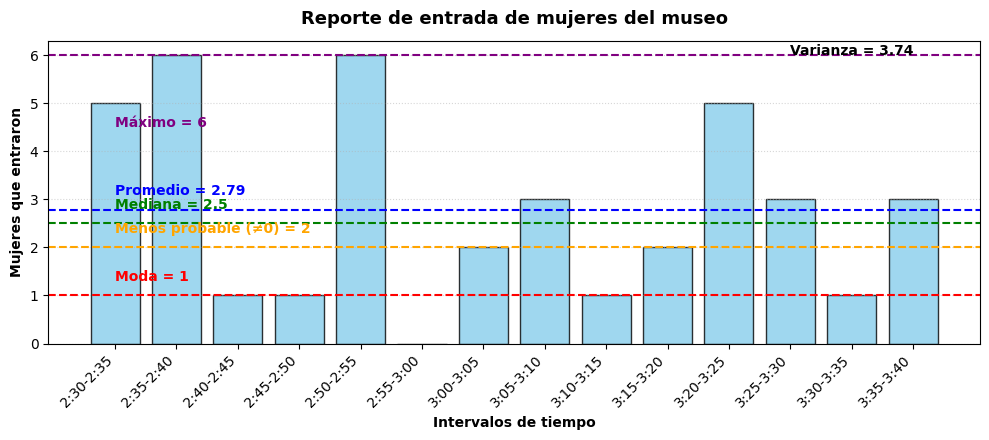

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

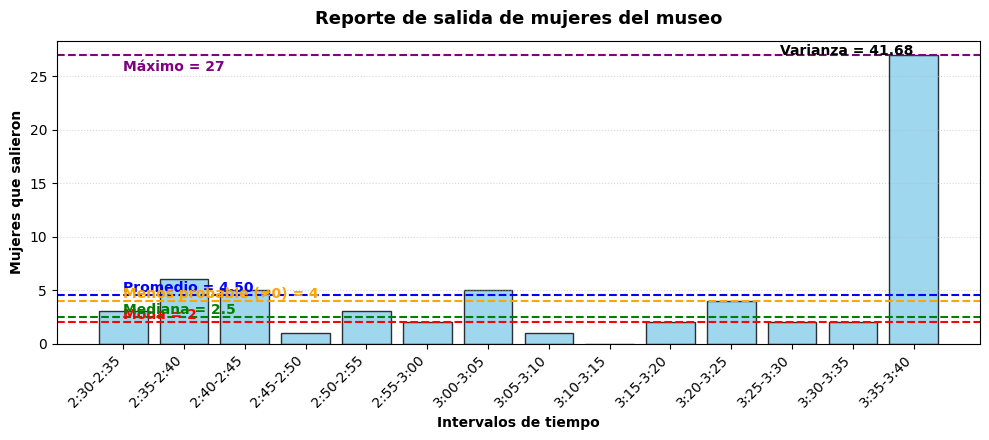

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

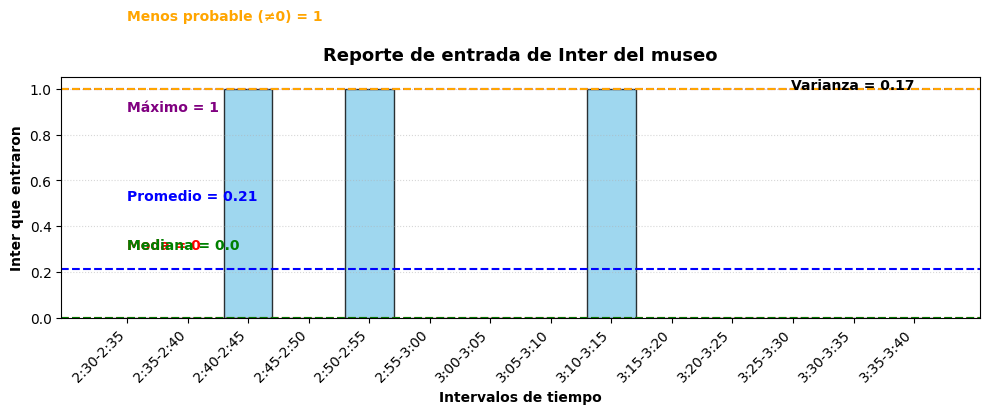

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

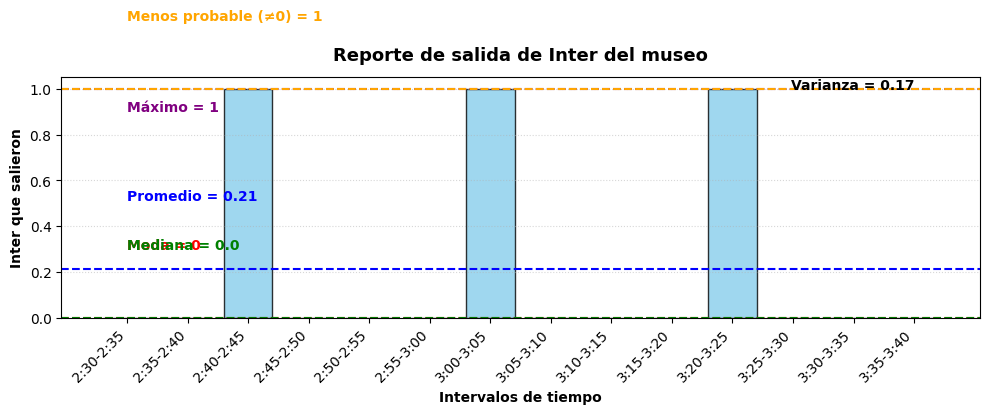

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

# 1. Crear los intervalos de tiempo una sola vez
intervalos = [f"{x}-{y}" for x, y in zip(hora_inicio, hora_fin)]

# =====================================================================
# CONFIGURACIÓN DE LOS REPORTES DEL MUSEO
# =====================================================================
# Estructura: (array_de_datos, "Título de la gráfica", "Etiqueta Eje Y", "nombre_archivo.png")
reportes_museo = [
    (entradas_hombres, 'Reporte de entrada de hombres del museo', 'Hombres que entraron', 'museo_entradas_hombres.png'),
    (salidas_hombres, 'Reporte de salida de hombres del museo', 'Hombres que salieron', 'museo_salidas_hombres.png'),
    (entradas_mujeres, 'Reporte de entrada de mujeres del museo', 'Mujeres que entraron', 'museo_entradas_mujeres.png'),
    (salidas_mujeres, 'Reporte de salida de mujeres del museo', 'Mujeres que salieron', 'museo_salidas_mujeres.png'),
    (entradas_inter, 'Reporte de entrada de Inter del museo', 'Inter que entraron', 'museo_entradas_inter.png'),
    (salidas_inter, 'Reporte de salida de Inter del museo', 'Inter que salieron', 'museo_salidas_inter.png')
]

# =====================================================================
# BUCLE AUTOMÁTICO DE PROCESAMIENTO Y ESTADÍSTICAS
# =====================================================================
for datos, titulo, eje_y, nombre_archivo in reportes_museo:

    # Configuración del lienzo con las medidas solicitadas (10, 4.5)
    plt.figure(figsize=(10, 4.5))
    plt.bar(intervalos, datos, color='skyblue', edgecolor='black', alpha=0.8)
    plt.xticks(rotation=45, ha='right')

    # ----- CÁLCULOS ESTADÍSTICOS -----
    valor_promedio = np.mean(datos)
    valor_varianza = np.var(datos)
    valor_mediana = np.median(datos)
    valor_maximo = np.max(datos)

    # Moda (Manejo seguro para Scipy)
    res_moda = stats.mode(datos)
    valor_moda = np.asarray(res_moda.mode).item()

    # Valor menos probable (excluyendo el cero)
    valores, conteos = np.unique(datos, return_counts=True)
    mascara_sin_cero = (valores != 0)
    if np.any(mascara_sin_cero):
        valores_sin_cero = valores[mascara_sin_cero]
        conteos_sin_cero = conteos[mascara_sin_cero]
        valor_menos_probable = valores_sin_cero[np.argmin(conteos_sin_cero)]
    else:
        valor_menos_probable = 0

    # ----- DIBUJAR LÍNEAS HORIZONTALES Y TEXTOS -----
    # Promedio
    plt.axhline(valor_promedio, color='blue', linestyle='--', linewidth=1.5)
    plt.text(0, valor_promedio + 0.3, f'Promedio = {valor_promedio:.2f}', color='blue', fontweight='bold')

    # Varianza (Ubicada arriba a la derecha para no obstruir las barras principales)
    plt.text(len(intervalos)-1, max(datos), f'Varianza = {valor_varianza:.2f}', color='black', fontweight='bold', ha='right')

    # Moda
    plt.axhline(valor_moda, color='red', linestyle='--', linewidth=1.5)
    plt.text(0, valor_moda + 0.3, f'Moda = {valor_moda}', color='red', fontweight='bold')

    # Mediana
    plt.axhline(valor_mediana, color='green', linestyle='--', linewidth=1.5)
    plt.text(0, valor_mediana + 0.3, f'Mediana = {valor_mediana}', color='green', fontweight='bold')

    # Máximo
    plt.axhline(valor_maximo, color='purple', linestyle='--', linewidth=1.5)
    offset_max = 1.5 if valor_maximo > 1.5 else valor_maximo * 0.1
    plt.text(0, valor_maximo - offset_max, f'Máximo = {valor_maximo}', color='purple', fontweight='bold')

    # Menos probable
    if valor_menos_probable != 0:
        plt.axhline(valor_menos_probable, color='orange', linestyle='--', linewidth=1.5)
        plt.text(0, valor_menos_probable + 0.3, f'Menos probable (≠0) = {valor_menos_probable}', color='orange', fontweight='bold')

    # ----- REFINAMIENTO VISUAL Y DESCARGA -----
    plt.xlabel('Intervalos de tiempo', fontweight='bold')
    plt.ylabel(eje_y, fontweight='bold')
    plt.title(titulo, fontsize=13, fontweight='bold', pad=12)
    plt.grid(axis='y', linestyle=':', alpha=0.5)  # Rejilla tenue de fondo para facilitar la lectura visual
    plt.tight_layout()

    # Guardar, mostrar en pantalla y gatillar descarga en Colab
    plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()
    files.download(nombre_archivo)
    plt.close()  # Limpia la memoria del lienzo gráfico antes de la siguiente iteración